In [18]:
import pandas as pd
from electricity_price_forecasting.data.data_pipeline import fetch_data

pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.max_colwidth", None)

In [118]:
_, _, df = fetch_data(pd.Timestamp("2024-07-01"), pd.Timestamp("2025-03-18"))

2025-03-19 12:08:53,746 - INFO - Fetching 'CZ' data from ENTSO-E...
2025-03-19 12:08:55,087 - INFO - Fetching data from OTE CR...
2025-03-19 12:08:55,915 - INFO - Fetching weather data...
2025-03-19 12:08:56,447 - INFO - Preprocessing data...
2025-03-19 12:08:56,739 - INFO - Data saved to 'merged.csv'
2025-03-19 12:08:57,391 - INFO - Quarterly data saved to 'quarterly.csv'
2025-03-19 12:08:57,461 - INFO - Hourly data saved to 'hourly.csv'


In [119]:
df.dropna(inplace=True)
display(df.head())

,Actual Aggregated,Actual Consumption,DA Price (EUR/MWh),DA Volume (MWh),Forecasted Load,ID Maximal price (EUR/MWh),ID Minimal price (EUR/MWh),ID Volume (MWh),ID Weighted average of the prices (EUR/MWh),Solar,direct_radiation,rain,wind_direction_10m,wind_direction_80m,wind_gusts_10m,wind_speed_10m,wind_speed_80m
2024-06-30 23:00:00+00:00,6094.50,0.0,83.01,2336.1,5210.25,94.0800,69.70,86.625,83.2350,0.00,0.0,0.0,274.460942,278.056533,16.649999,7.142880,14.916759
2024-07-01 00:00:00+00:00,5704.25,0.0,76.59,2495.3,5054.00,88.6925,68.20,154.400,75.9450,0.00,0.0,0.0,263.322230,266.964038,16.739999,7.803378,15.630196
2024-07-01 01:00:00+00:00,5700.50,0.0,75.52,2585.2,4973.25,89.8250,20.00,127.475,76.9525,0.00,0.0,0.0,258.112062,260.932540,18.720000,8.370291,16.771195
2024-07-01 02:00:00+00:00,5824.75,0.0,71.97,2586.3,5039.25,88.5000,57.80,192.075,75.2325,5.25,0.0,0.0,262.701390,265.773200,22.319999,9.982403,19.584927
2024-07-01 03:00:00+00:00,6151.50,0.0,76.97,2431.9,5374.00,108.0050,51.97,225.750,78.3325,32.25,0.5,0.0,269.050263,271.527490,24.479999,10.179417,18.660174


In [21]:
display(df.describe())

,Actual Aggregated,Actual Consumption,DA Price (EUR/MWh),DA Volume (MWh),Forecasted Load,ID Maximal price (EUR/MWh),ID Minimal price (EUR/MWh),ID Volume (MWh),ID Weighted average of the prices (EUR/MWh),Solar,direct_radiation,rain,wind_direction_10m,wind_direction_80m,wind_gusts_10m,wind_speed_10m,wind_speed_80m
count,6230.000000,6230.0,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000,6230.000000
mean,7934.704013,0.0,106.541555,3381.159117,7172.658106,189.855252,43.562609,155.181998,105.659499,399.762881,54.097030,0.012030,194.437071,197.098216,21.252120,9.501978,18.516392
std,1832.385406,0.0,57.071808,770.459502,1386.641999,223.641457,82.545259,83.444215,63.019343,662.671552,123.044609,0.083046,86.670345,86.093765,10.326289,4.614842,8.627084
min,18.750000,0.0,-81.160000,1525.100000,3955.250000,-9.242500,-4177.950000,0.025000,-408.720000,0.000000,0.000000,0.000000,1.684657,0.940440,2.160000,0.508525,0.561838
25%,6950.125000,0.0,80.762500,2840.350000,6160.000000,123.320000,16.078750,94.756250,77.088125,0.000000,0.000000,0.000000,120.739489,125.923962,13.320000,6.047487,12.385540
50%,8012.250000,0.0,105.020000,3337.100000,7153.125000,158.711250,48.216250,141.125000,101.233750,4.500000,0.000000,0.000000,202.869055,207.896482,19.620000,8.822814,17.950861
75%,9089.000000,0.0,130.742500,3881.275000,8141.500000,199.990000,78.726250,198.500000,128.663750,544.500000,24.000000,0.000000,266.058796,267.918171,27.720000,12.407028,23.924129
max,13091.000000,0.0,844.630000,6084.800000,10831.500000,9998.980000,386.652500,767.925000,1349.005000,2915.500000,739.750000,3.200000,360.000000,360.000000,68.939999,27.273541,51.406869


In [120]:
df.drop(columns=["Actual Consumption"], inplace=True)

In [121]:
df['hour'] = df.index.hour
df['dayofweek'] = df.index.dayofweek
df['month'] = df.index.month
df['dayofyear'] = df.index.dayofyear
df['weekofyear'] = df.index.isocalendar().week
df['year'] = df.index.year

In [24]:
train_size = int(len(df) * 0.8)
train, test = df.iloc[:train_size], df.iloc[train_size:]

In [30]:
features = [
    "DA Price (EUR/MWh)", "DA Volume (MWh)", "Forecasted Load", "Solar", "rain",
    "wind_direction_10m", "wind_direction_80m", "wind_gusts_10m", "wind_speed_10m", "wind_speed_80m"
]

target = 'ID Weighted average of the prices (EUR/MWh)'

In [31]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

lr = LinearRegression()
lr.fit(train[features], train[target])

ridge = Ridge(alpha=1.0)
ridge.fit(train[features], train[target])

lasso = Lasso(alpha=0.01)
lasso.fit(train[features], train[target])

elastic = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic.fit(train[features], train[target])

ElasticNet(alpha=0.1)

In [32]:
lr_preds = lr.predict(test[features])
ridge_preds = ridge.predict(test[features])
lasso_preds = lasso.predict(test[features])
elastic_preds = elastic.predict(test[features])


In [33]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate(model_name, actual, predicted):
    mse = mean_squared_error(actual, predicted)
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    print(f'{model_name} - MSE: {mse:.2f}, MAE: {mae:.2f}, R2: {r2:.2f}')

evaluate('Linear Regression', test[target], lr_preds)
evaluate('Ridge', test[target], ridge_preds)
evaluate('Lasso', test[target], lasso_preds)
evaluate('ElasticNet', test[target], elastic_preds)

Linear Regression - MSE: 573.56, MAE: 18.01, R2: 0.69
Ridge - MSE: 573.55, MAE: 18.01, R2: 0.69
Lasso - MSE: 573.42, MAE: 18.00, R2: 0.69
ElasticNet - MSE: 572.87, MAE: 17.98, R2: 0.69


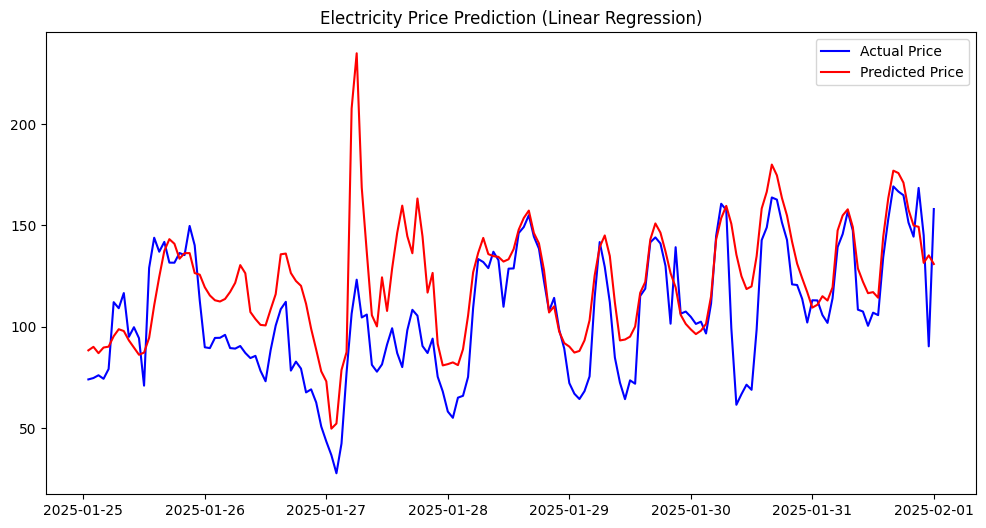

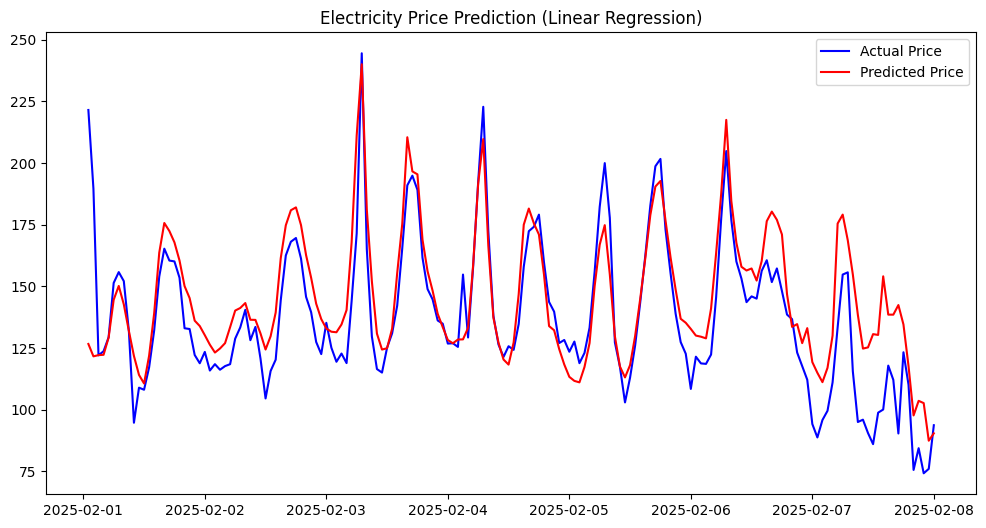

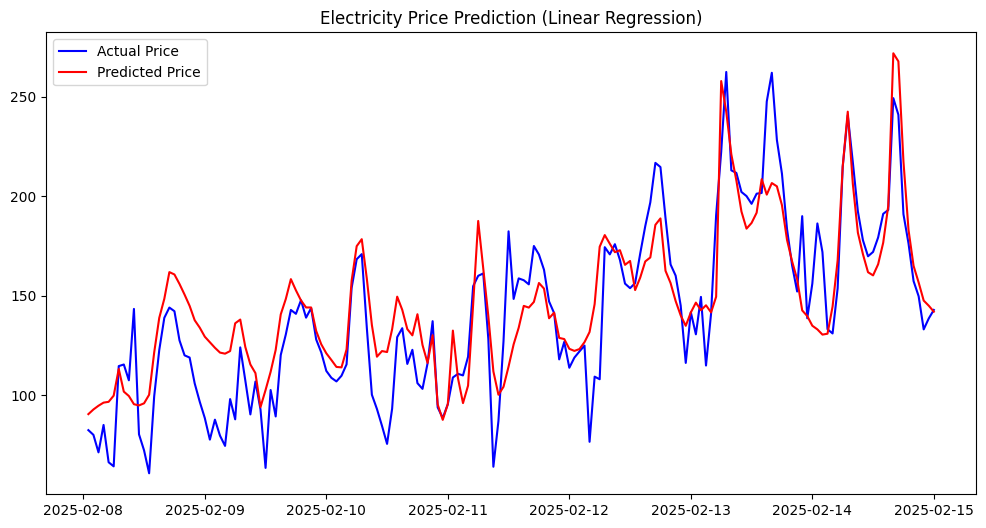

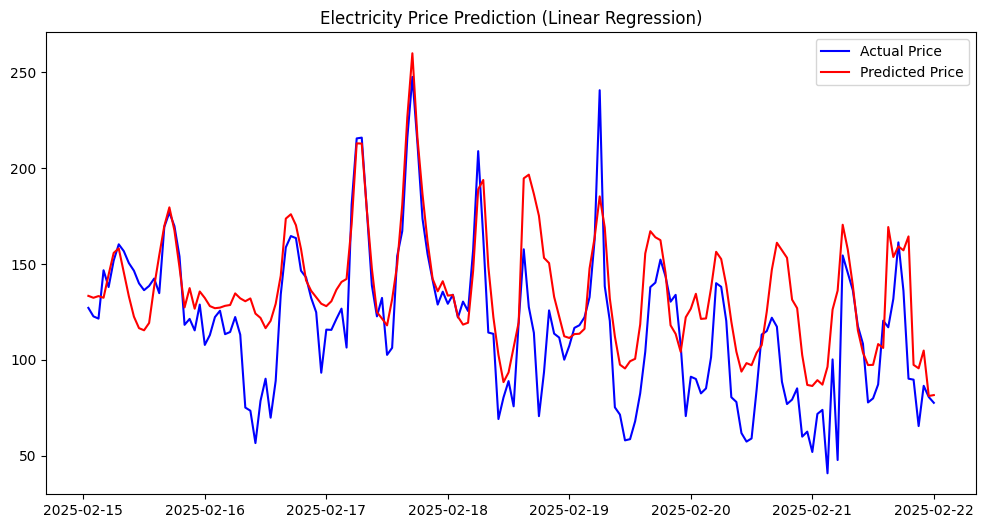

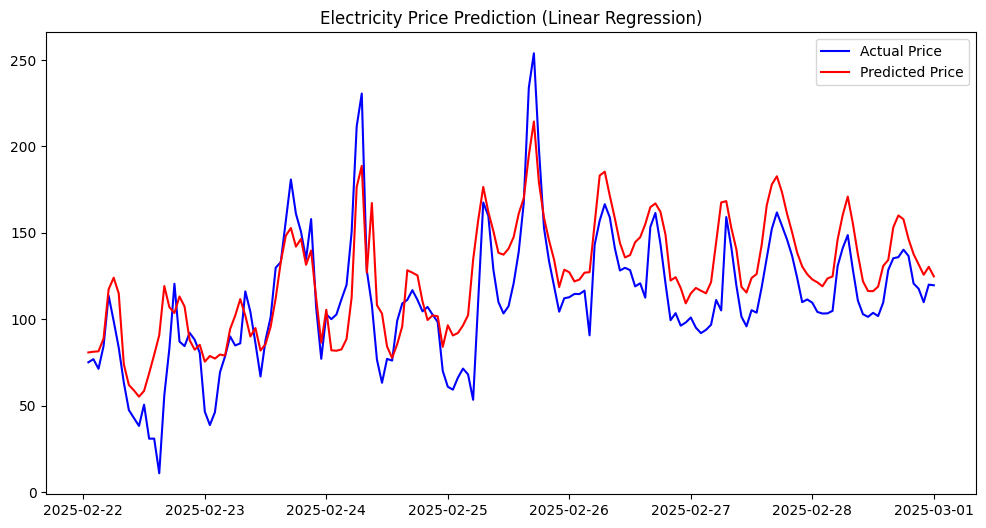

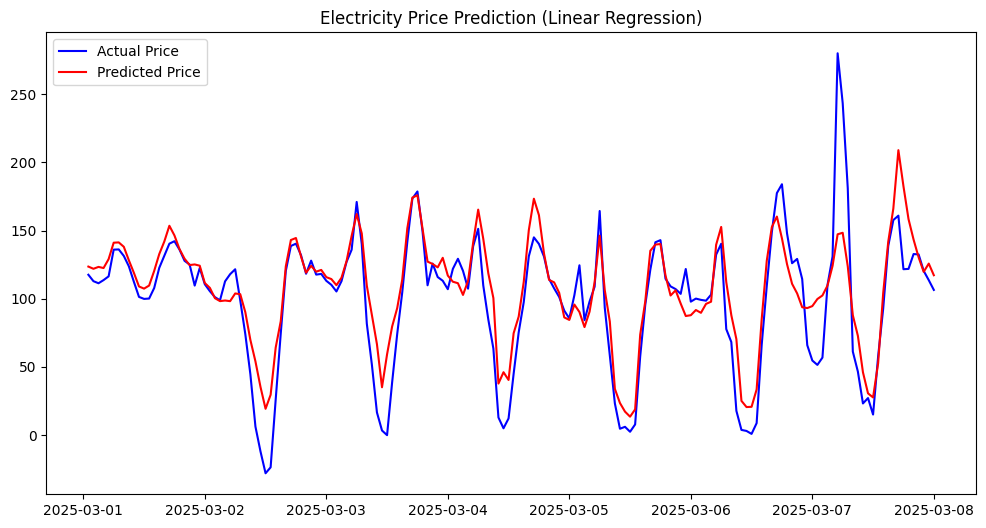

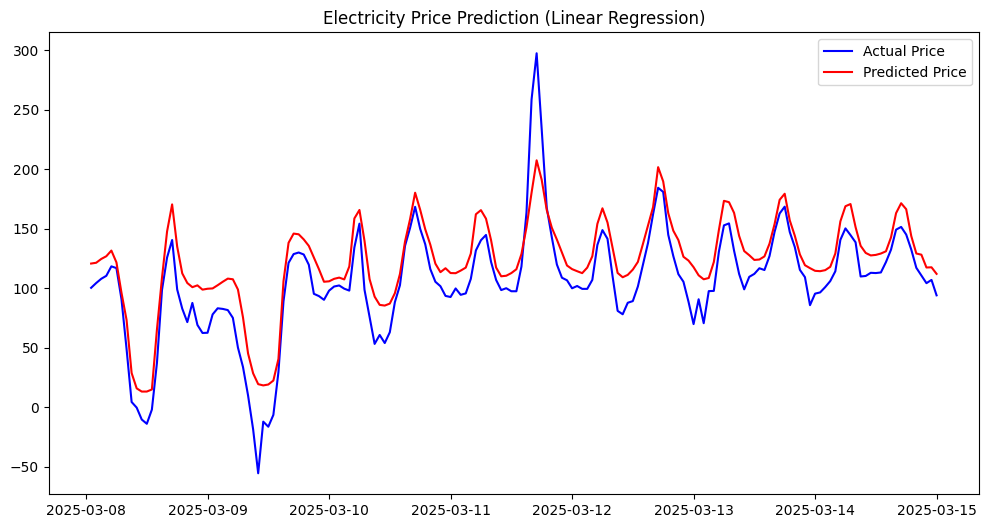

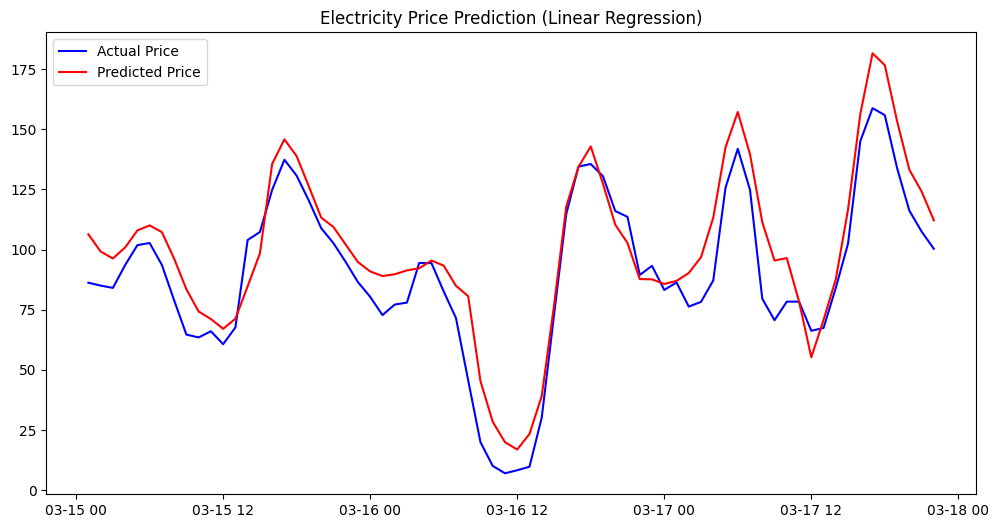

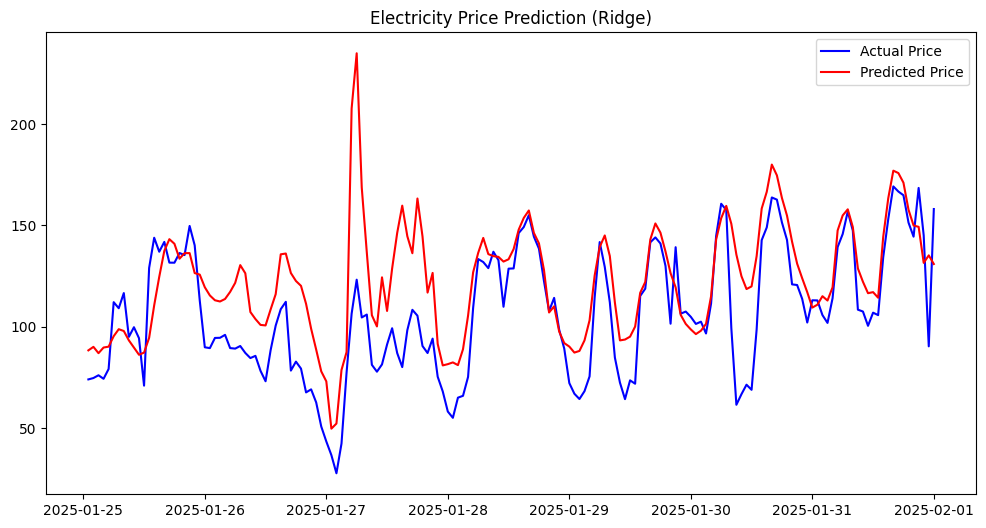

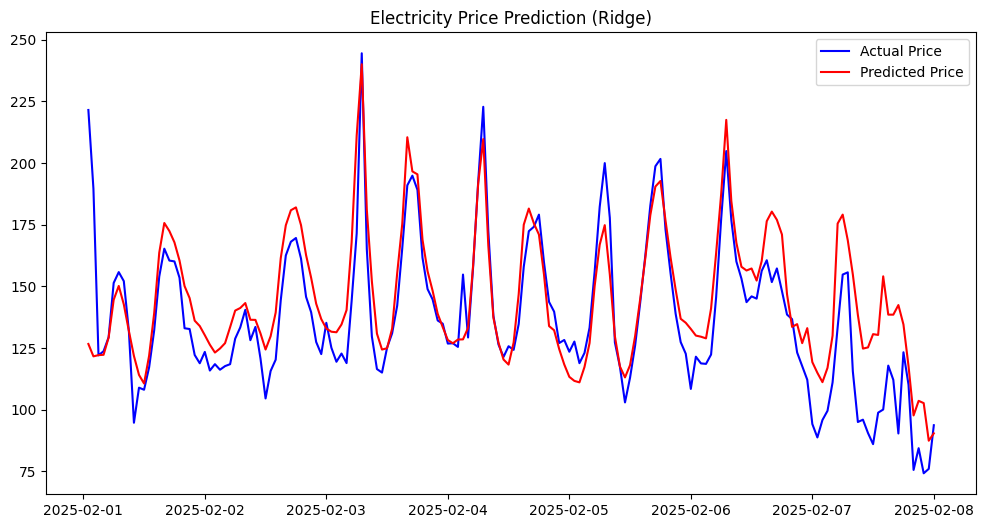

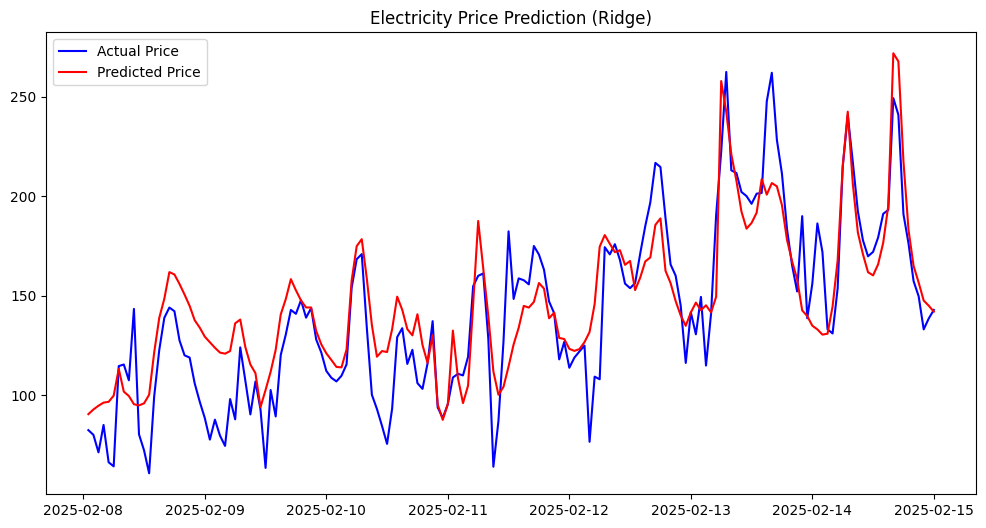

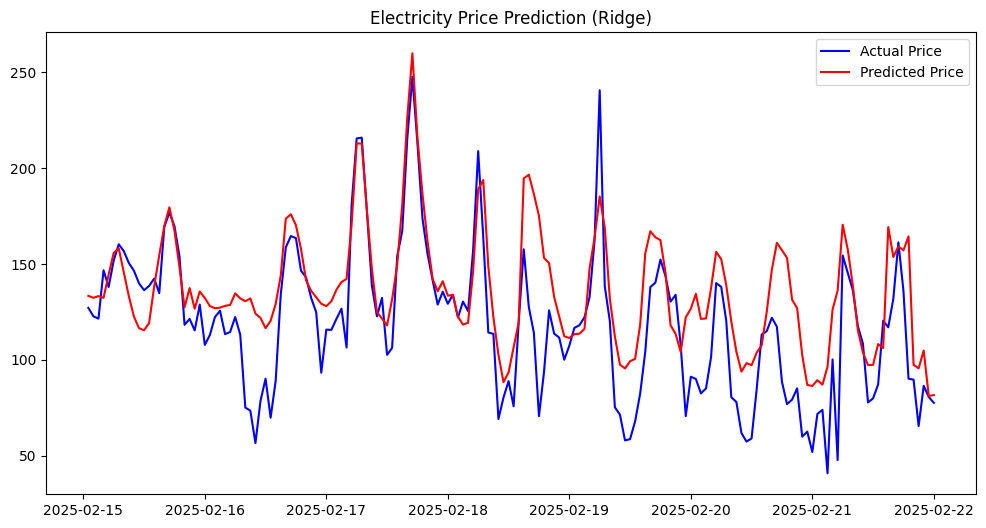

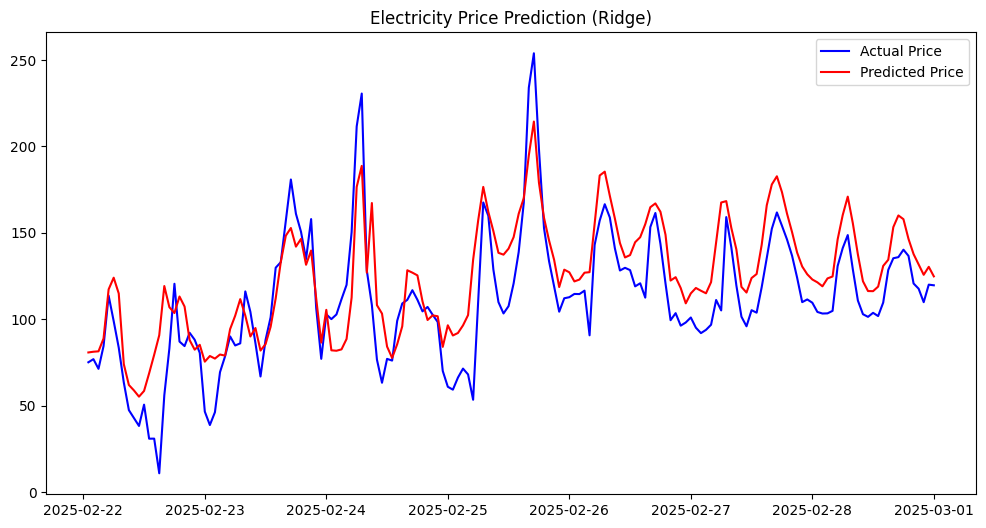

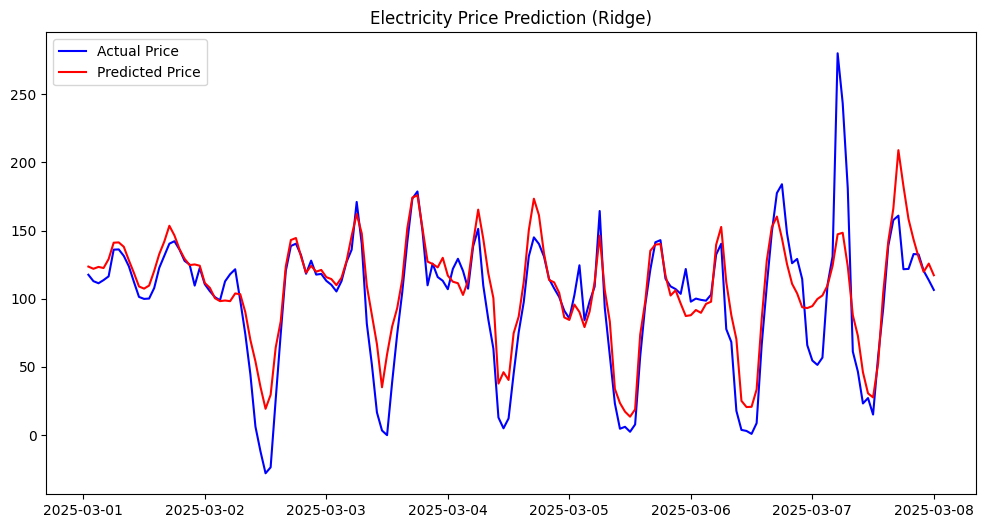

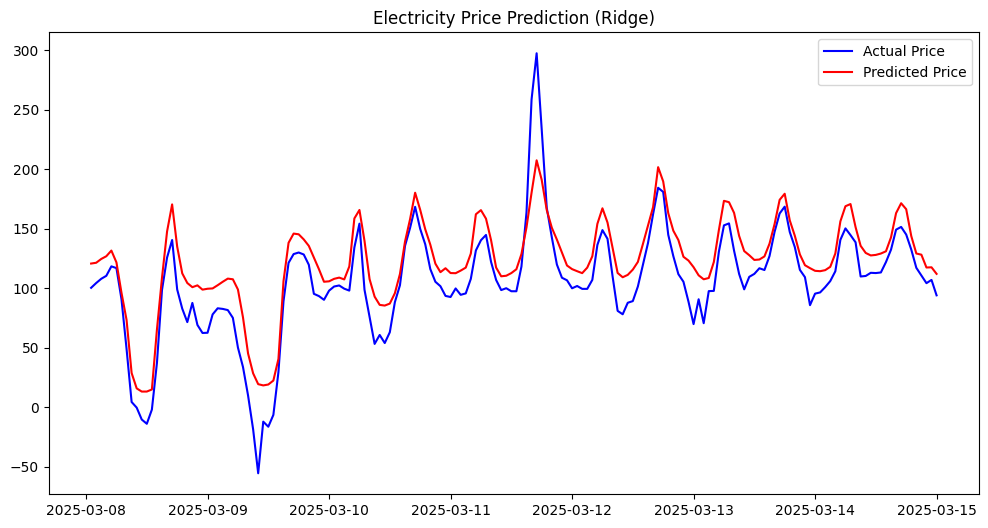

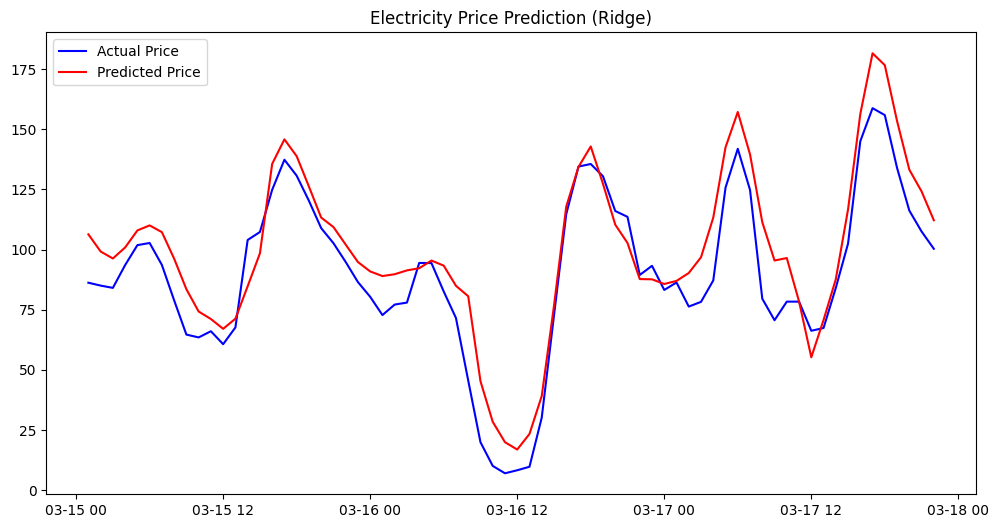

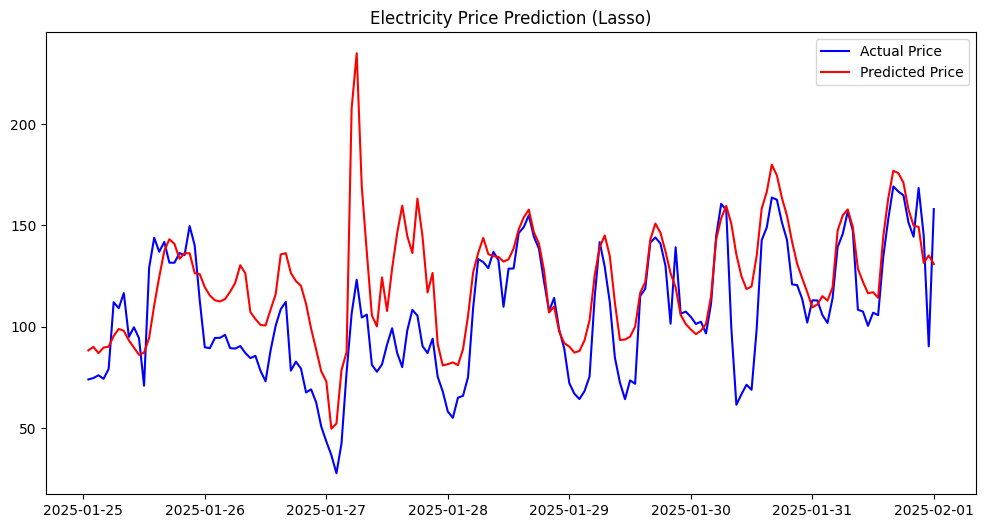

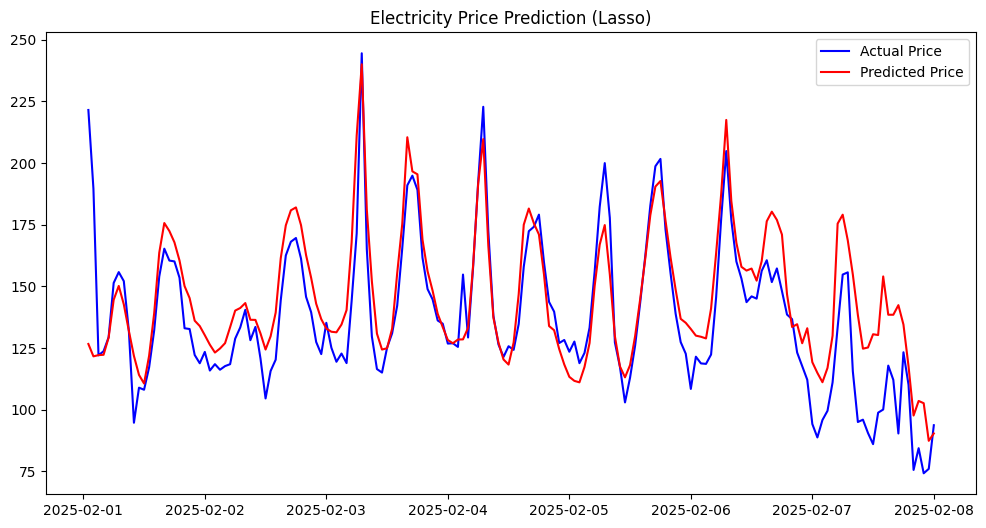

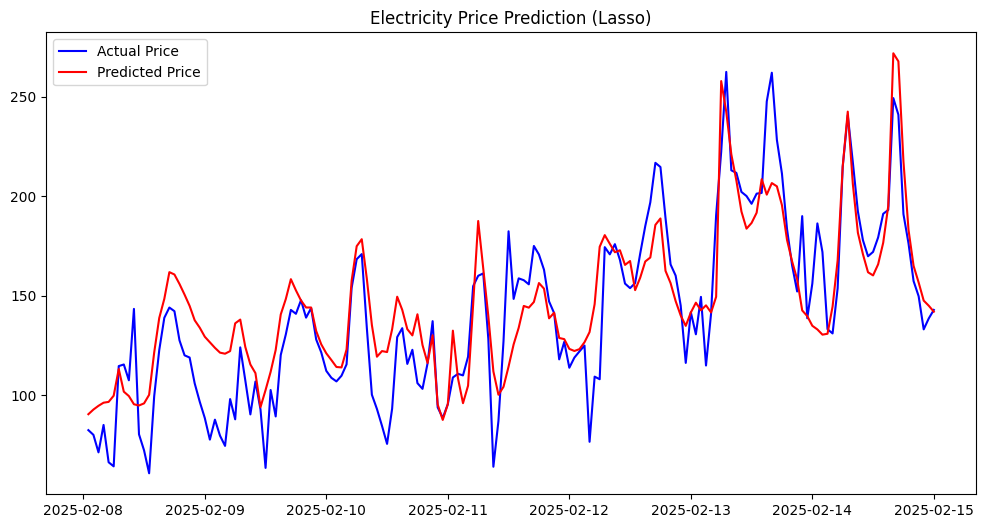

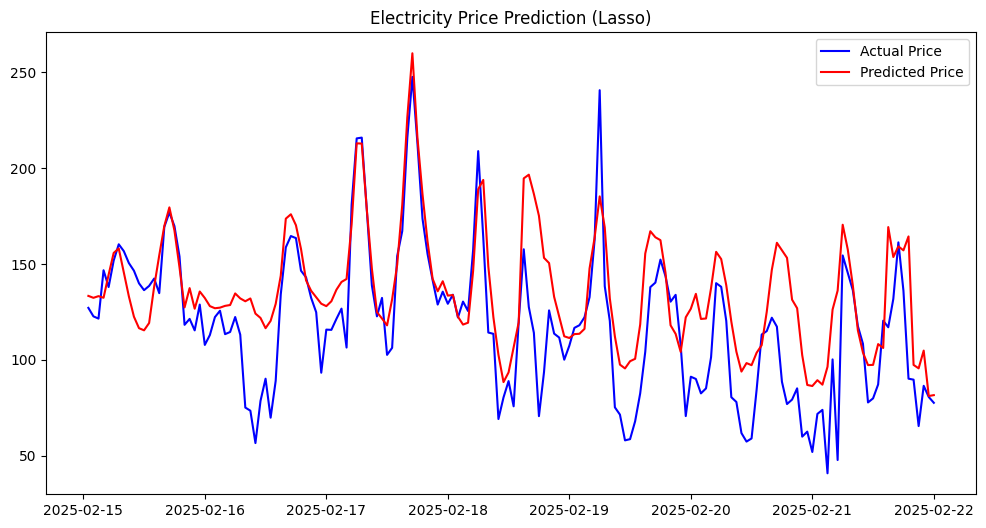

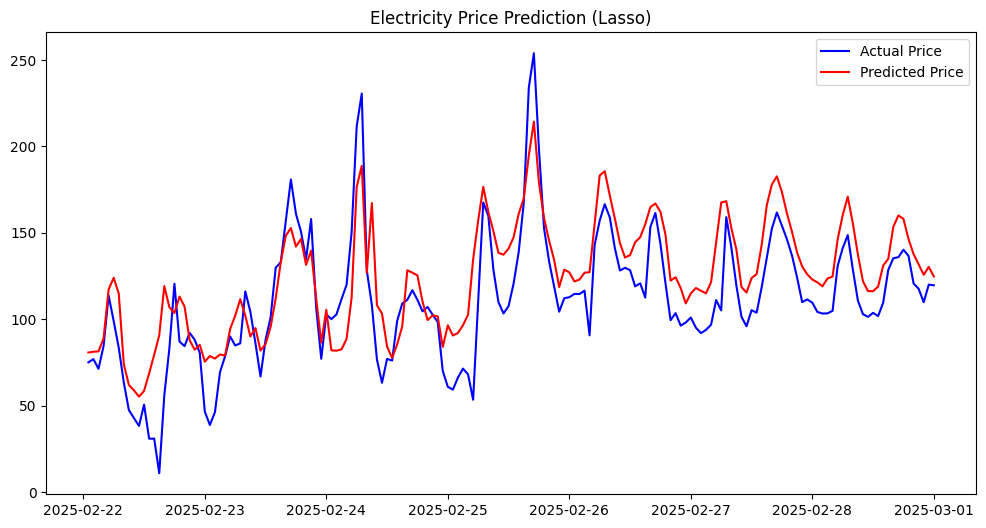

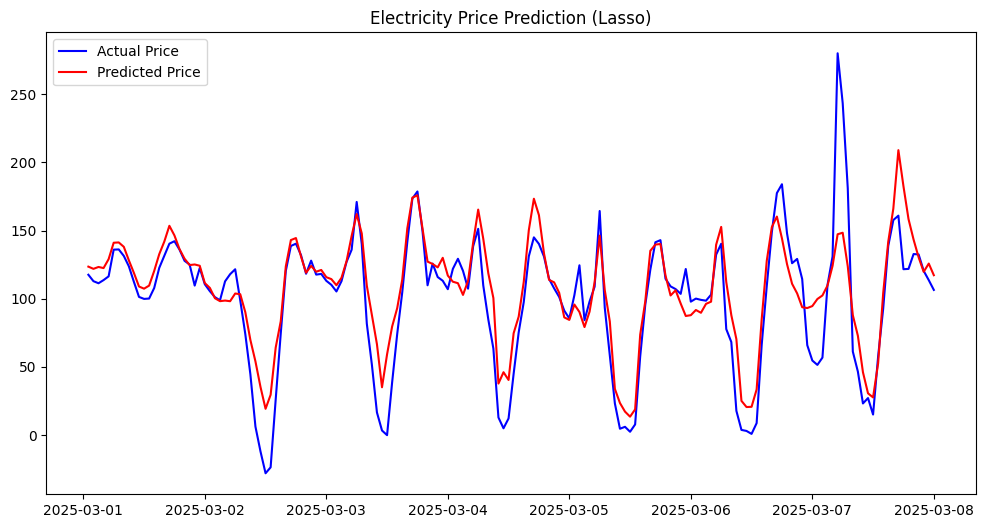

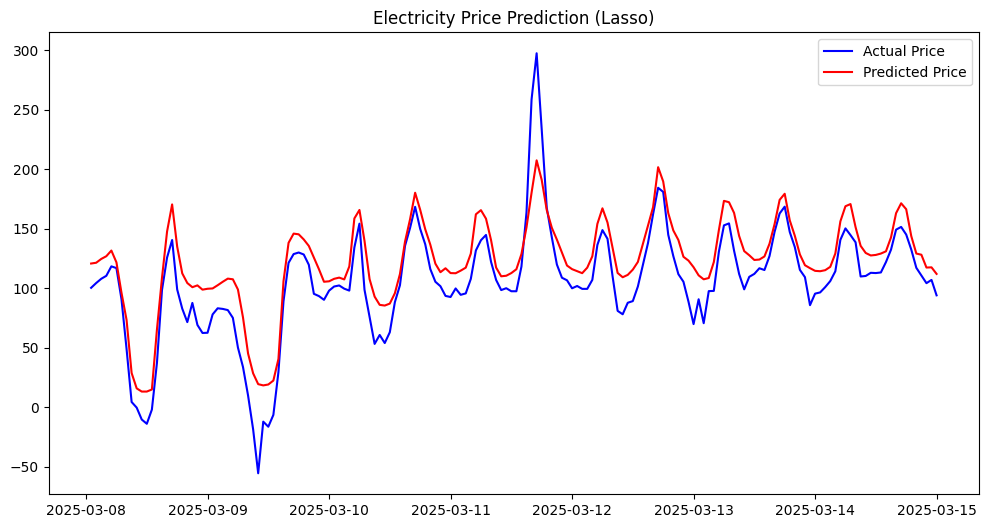

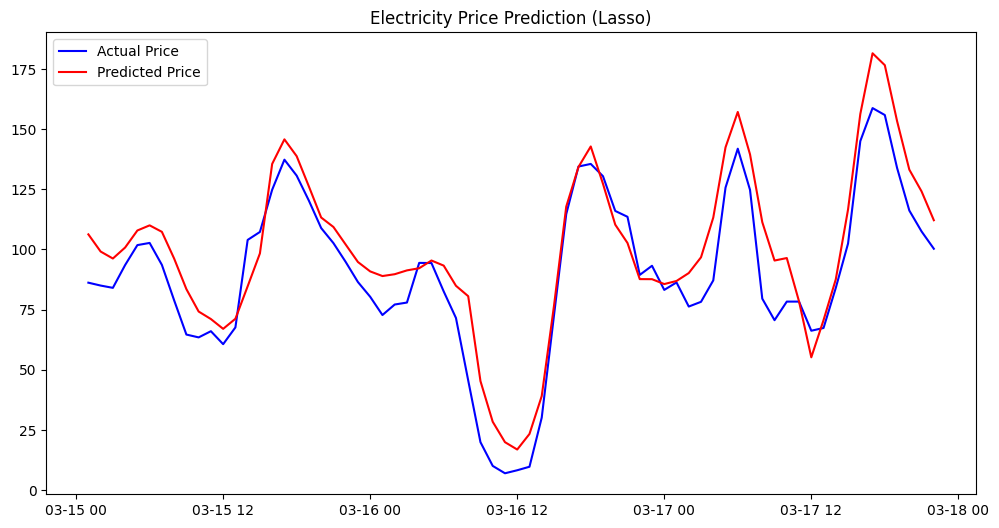

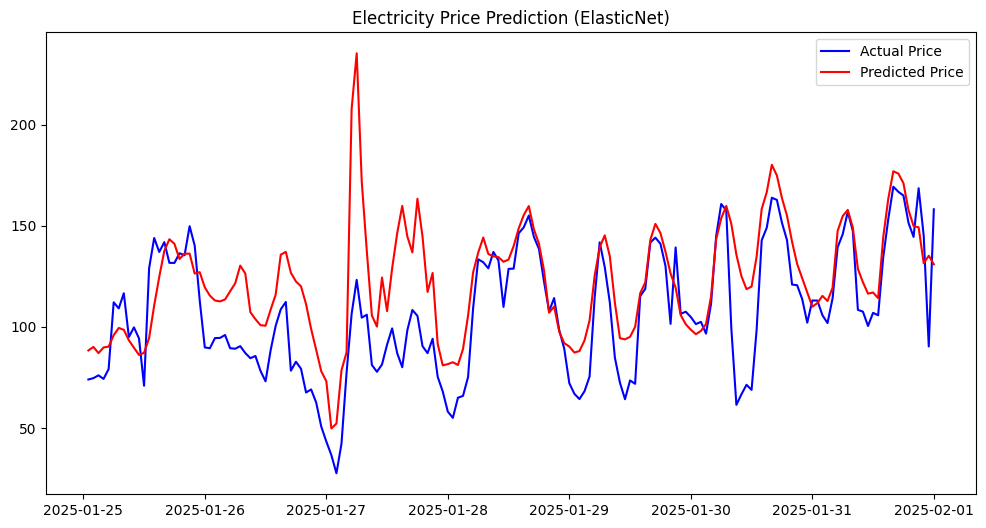

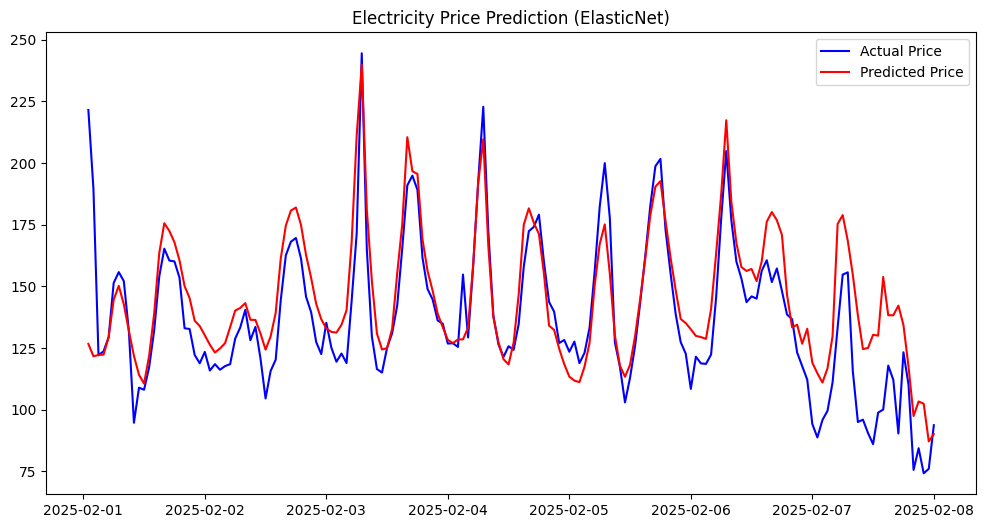

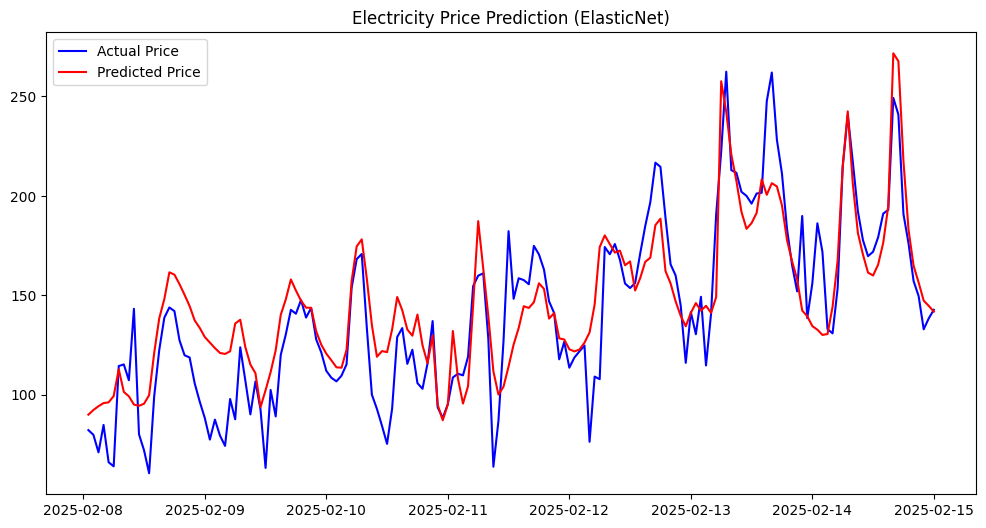

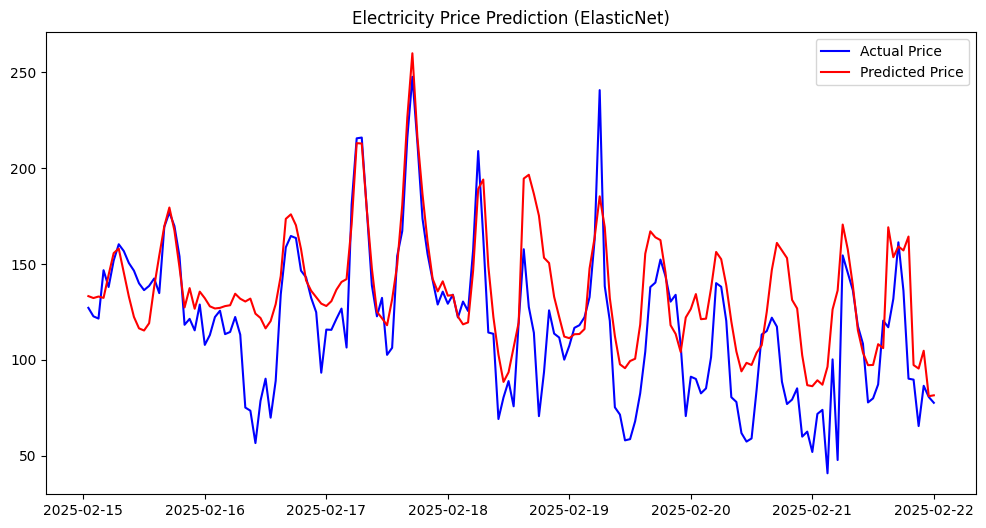

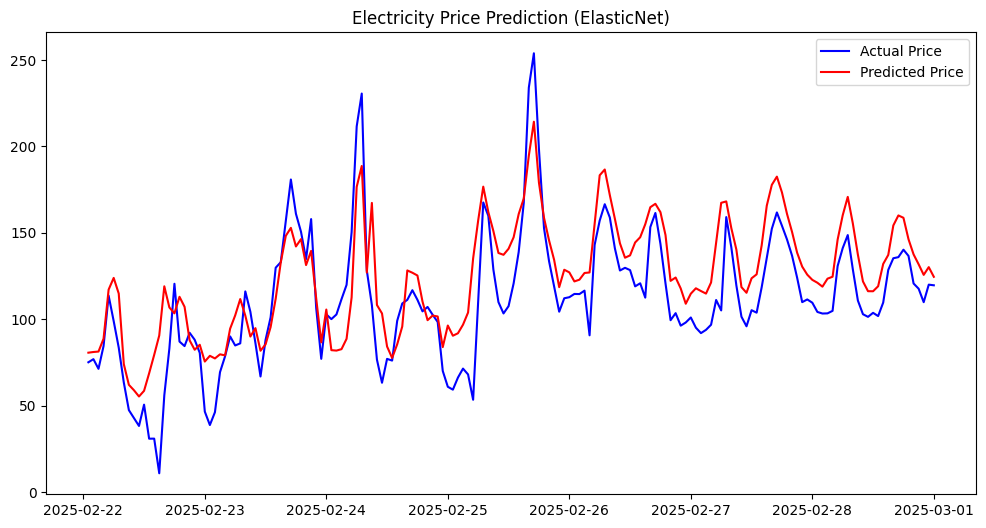

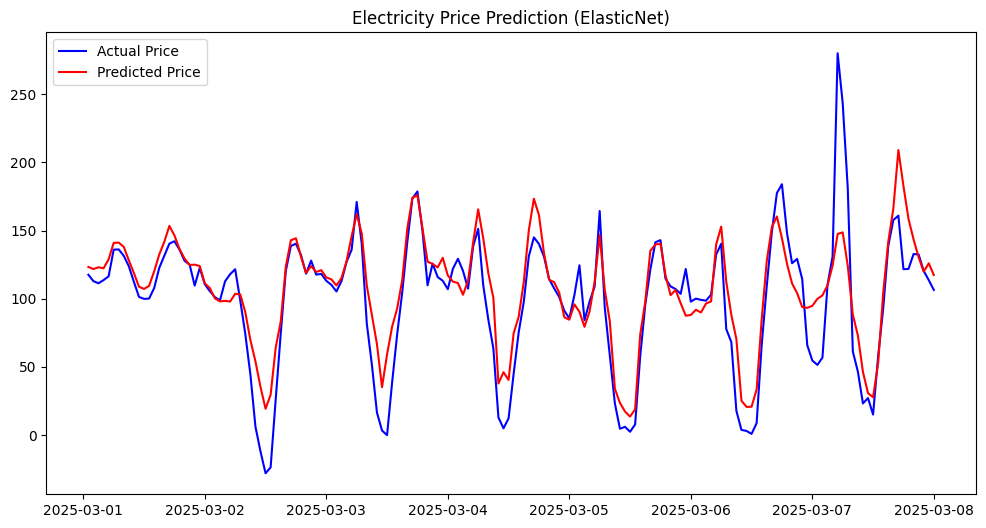

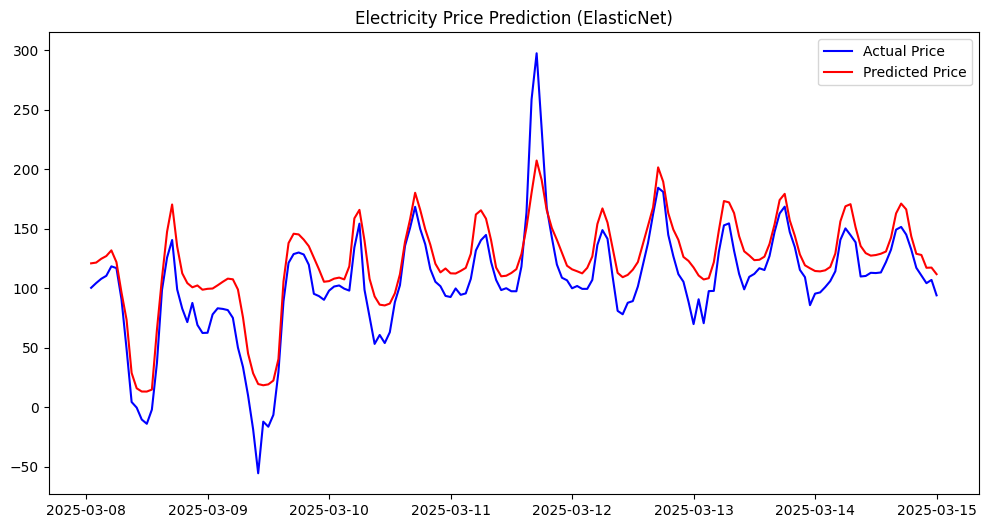

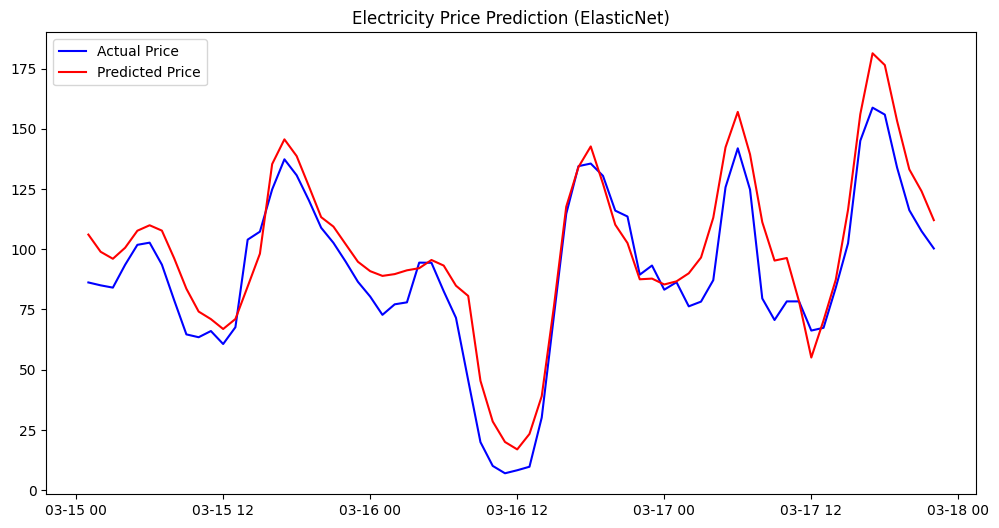

In [34]:
import matplotlib.pyplot as plt

def plot(model_name, actual, predicted):
    for start in range(0, len(actual.index), 168):
        end = start + 168
        index = actual.index[start:end]
        y_test = actual[target][start:end]
        y_pred = predicted[start:end]

        plt.figure(figsize=(12, 6))
        plt.plot(index, y_test, label='Actual Price', color='blue')
        plt.plot(index, y_pred, label='Predicted Price', color='red')
        plt.title(f'Electricity Price Prediction ({model_name})')
        plt.legend()
        plt.show()

plot('Linear Regression', test, lr_preds)
plot('Ridge', test, ridge_preds)
plot('Lasso', test, lasso_preds)
plot('ElasticNet', test, elastic_preds)

In [39]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'alpha': [0.01, 0.1, 1, 10, 100, 1000],
    'l1_ratio': [0.001, 0.01, 0.1, 0.5, 0.7, 0.9, 1]
}

elastic = ElasticNet(max_iter=10000)
grid = GridSearchCV(estimator=elastic, param_grid=param_grid, cv=5, scoring='neg_mean_squared_error', verbose=1, n_jobs=-1)
grid.fit(train[features], train[target])

print(f"Best alpha: {grid.best_params_['alpha']}")
print(f"Best l1_ratio: {grid.best_params_['l1_ratio']}")

Fitting 5 folds for each of 42 candidates, totalling 210 fits
Best alpha: 100
Best l1_ratio: 0.01


In [40]:
best_elastic = ElasticNet(
    alpha=grid.best_params_['alpha'],
    l1_ratio=grid.best_params_['l1_ratio'],
    max_iter=10000
)

best_elastic.fit(train[features], train[target])

ElasticNet(alpha=100, l1_ratio=0.01, max_iter=10000)

In [41]:
grid_elastic_preds = best_elastic.predict(test[features])

In [42]:
evaluate("ElasticNet", test[target], grid_elastic_preds)

ElasticNet - MSE: 571.74, MAE: 17.73, R2: 0.69


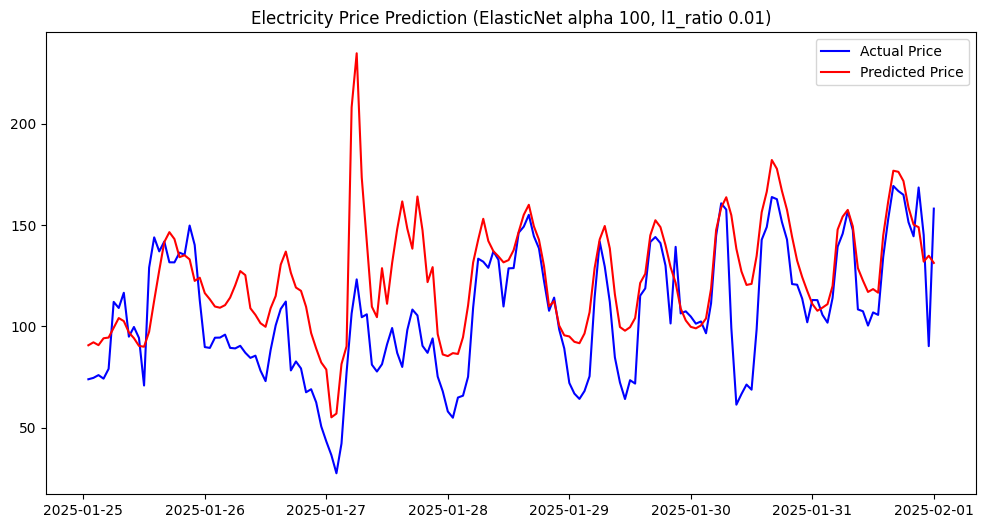

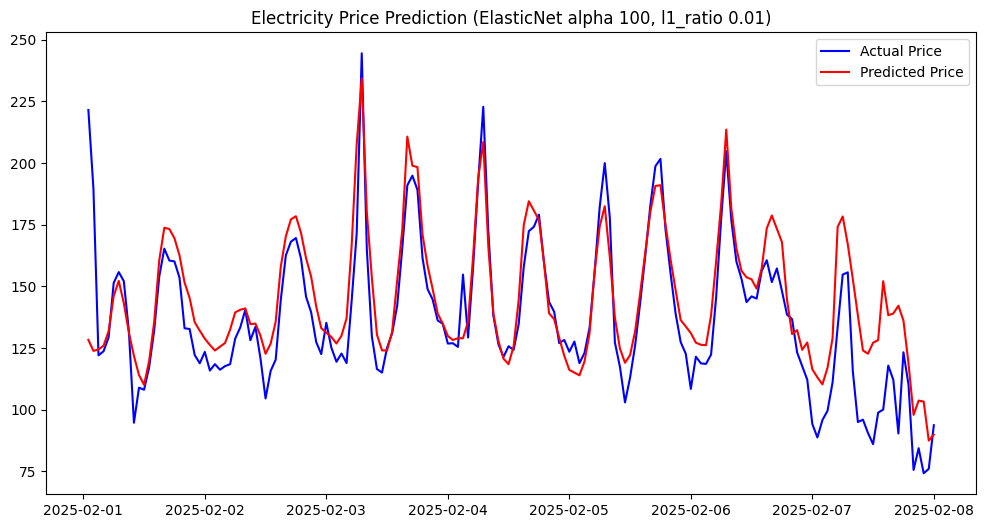

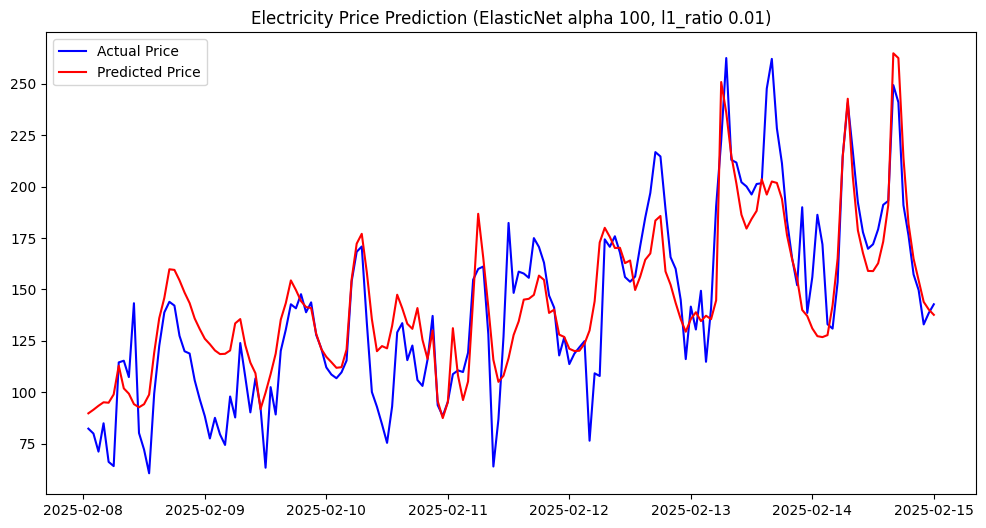

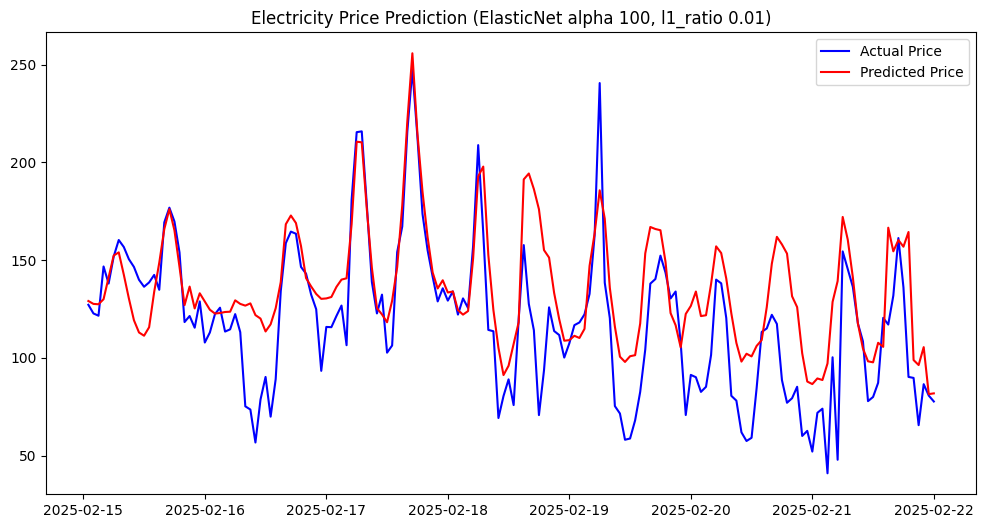

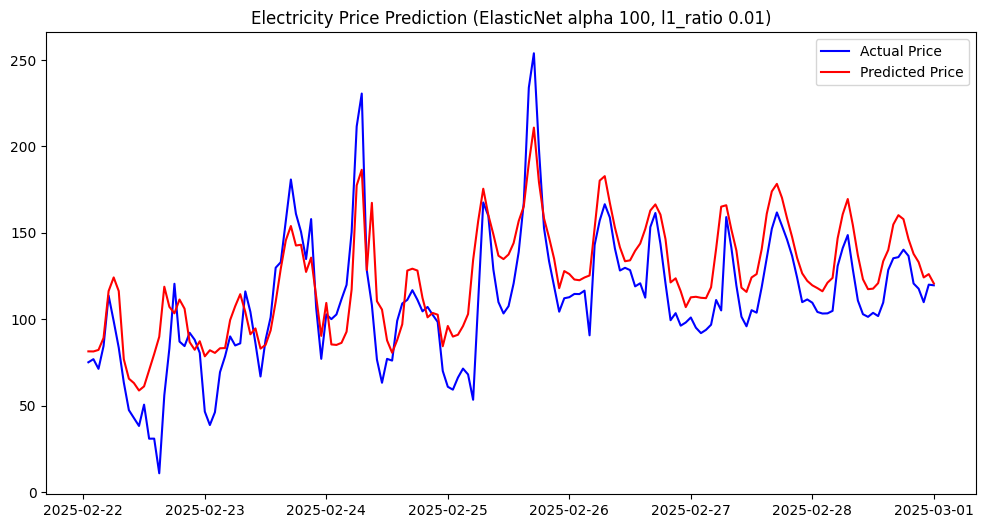

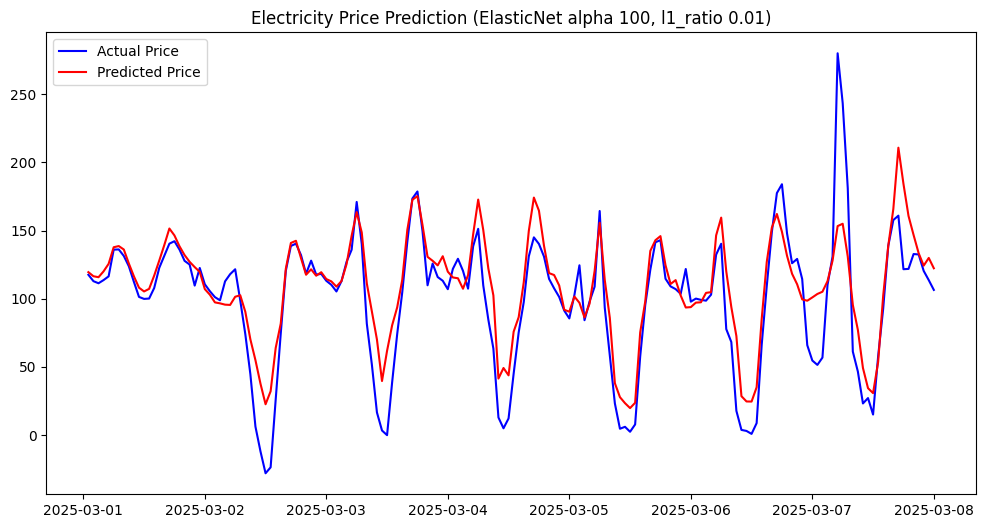

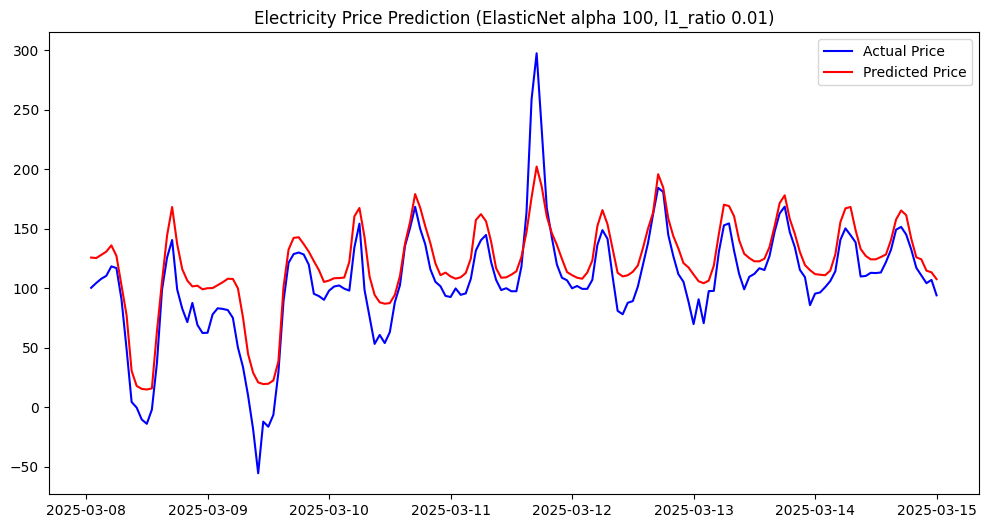

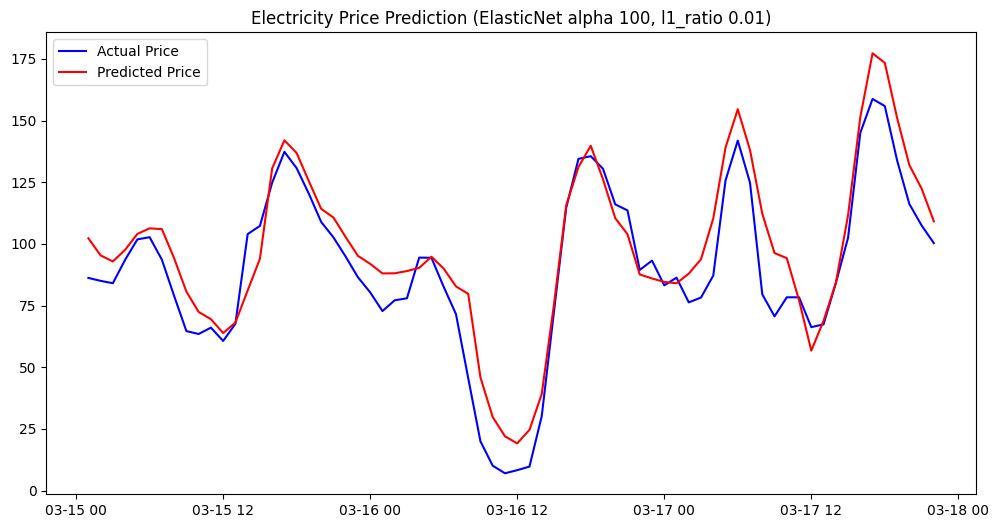

In [44]:
plot(f"ElasticNet alpha {grid.best_params_['alpha']}, l1_ratio {grid.best_params_['l1_ratio']}", test, grid_elastic_preds)

In [46]:
from sklearn.feature_selection import RFECV

elastic_selection = ElasticNet(
    alpha=grid.best_params_['alpha'],
    l1_ratio=grid.best_params_['l1_ratio'],
    max_iter=10000
)

selector = RFECV(
    estimator=elastic_selection,
    step=1,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

features_selection = [feature for feature in features if feature != "DA Price (EUR/MWh)"]

selector.fit(train[features_selection], train[target])

selected_features = [feature for feature, selected in zip(features_selection, selector.support_) if selected]
print(f"Selected features: {selected_features}")

not_selected_features = [feature for feature, selected in zip(features_selection, selector.support_) if not selected]
print(f"Not selected features: {not_selected_features}")

Selected features: ['DA Volume (MWh)', 'Forecasted Load', 'Solar', 'wind_direction_10m', 'wind_direction_80m', 'wind_gusts_10m', 'wind_speed_10m', 'wind_speed_80m']
Not selected features: ['rain']


In [47]:
elastic_no_da = ElasticNet(
    alpha=grid.best_params_['alpha'],
    l1_ratio=grid.best_params_['l1_ratio'],
    max_iter=10000
)

elastic_no_da.fit(train[features_selection], train[target])

ElasticNet(alpha=100, l1_ratio=0.01, max_iter=10000)

In [49]:
elastic_no_da_preds = elastic_no_da.predict(test[features_selection])

In [50]:
evaluate("ElasticNet (Without Day-ahead prices)", test[target], elastic_no_da_preds)

ElasticNet (Without Day-ahead prices) - MSE: 1604.19, MAE: 34.14, R2: 0.13


In [66]:
elastic_only_da = ElasticNet(
    alpha=grid.best_params_['alpha'],
    l1_ratio=grid.best_params_['l1_ratio'],
    max_iter=10000
)
features_only_da = ["DA Price (EUR/MWh)"]
elastic_only_da.fit(train[features_only_da], train[target])
elastic_only_da_preds = elastic_only_da.predict(test[features_only_da])
evaluate("ElasticNet (With only Day-ahead prices)", test[target], elastic_only_da_preds)

evaluate("DA vs ID", test[target], test[features_only_da])

ElasticNet (With only Day-ahead prices) - MSE: 484.24, MAE: 15.20, R2: 0.74
DA vs ID - MSE: 484.13, MAE: 15.10, R2: 0.74


In [53]:
average_price = train[target].mean()
print(f"Average price: {average_price:.2f}")
evaluate("Average price", test[target], [average_price for _ in range(len(test[target]))])

Average price: 103.19
Average price - MSE: 1999.75, MAE: 33.51, R2: -0.08


In [64]:
average_price_hourly = df.groupby(df.index.hour)[target].mean()
evaluate("Average price (hourly)", test[target], [average_price_hourly[hour] for hour in test.hour])

Average price (hourly) - MSE: 1477.77, MAE: 29.15, R2: 0.20


In [69]:
average_train_price_hourly = train.groupby(train.index.hour)[target].mean()
evaluate("Average train price (hourly)", test[target], [average_train_price_hourly[hour] for hour in test.hour])

Average train price (hourly) - MSE: 1563.66, MAE: 30.26, R2: 0.15


In [70]:
from sklearn.svm import SVR

param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svr = SVR()

grid_search = GridSearchCV(
    estimator=svr,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=4
)

grid_search.fit(train[features], train[target])
print("Best Params:", grid_search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Params: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}


In [72]:
best_svr = SVR(
    C=grid_search.best_params_['C'],
    kernel=grid_search.best_params_['kernel'],
    gamma=grid_search.best_params_['gamma'],
    degree=grid_search.best_params_.get('degree', 3)
)

best_svr.fit(train[features], train[target])

SVR(C=0.1, kernel='linear')

In [74]:
svr_preds = best_svr.predict(test[features])

evaluate("SVR", test[target], svr_preds)

SVR - MSE: 491.45, MAE: 15.72, R2: 0.73


In [88]:
expanding_window = train.copy()

predictions = []

for i in range(len(test)):
    for lag in range(1, 4):
        expanding_window[f'lag_{lag}'] = expanding_window[target].shift(lag)

    expanding_window = expanding_window.dropna()

    model = LinearRegression()
    model.fit(expanding_window[features], expanding_window[target])

    last_known = test.iloc[i][features].values
    pred = model.predict(last_known.reshape(1, -1))[0]

    predictions.append(pred)

    new_row = test.iloc[i]
    df.loc[len(df.index)] = new_row

/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation

In [89]:
evaluate("Expanding window", test[target], predictions)

Expanding window - MSE: 616.30, MAE: 18.99, R2: 0.67


In [123]:
lagged_df = df.copy()

for lag in range(1, 168 + 1):
    lagged_df[f'price_lag_{lag}'] = df[target].shift(lag)

for day in range(1, 29):
    lagged_df[f'max_price_lag_{day}'] = (
        lagged_df["ID Maximal price (EUR/MWh)"]
        .resample('D').max().shift(day).reindex(lagged_df.index, method='ffill')
    )
    lagged_df[f'min_price_lag_{day}'] = (
        lagged_df["ID Minimal price (EUR/MWh)"]
        .resample('D').min().shift(day).reindex(lagged_df.index, method='ffill')
    )
    lagged_df[f'avg_price_lag_{day}'] = (
        lagged_df["ID Weighted average of the prices (EUR/MWh)"]
        .resample('D').mean().shift(day).reindex(lagged_df.index, method='ffill')
    )

/var/folders/yb/nq6qgkjd1r1gbjptj_jtzsc80000gn/T/ipykernel_31526/739995498.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lagged_df[f'price_lag_{lag}'] = df[target].shift(lag)
/var/folders/yb/nq6qgkjd1r1gbjptj_jtzsc80000gn/T/ipykernel_31526/739995498.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lagged_df[f'price_lag_{lag}'] = df[target].shift(lag)
/var/folders/yb/nq6qgkjd1r1gbjptj_jtzsc80000gn/T/ipykernel_31526/739995498.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling 

In [131]:
lagged_df = lagged_df.copy()
lagged_df.dropna(inplace=True)
lagged_df.head()

,Actual Aggregated,DA Price (EUR/MWh),DA Volume (MWh),Forecasted Load,ID Maximal price (EUR/MWh),ID Minimal price (EUR/MWh),ID Volume (MWh),ID Weighted average of the prices (EUR/MWh),Solar,direct_radiation,rain,wind_direction_10m,wind_direction_80m,wind_gusts_10m,wind_speed_10m,wind_speed_80m,hour,dayofweek,month,dayofyear,weekofyear,year,price_lag_1,price_lag_2,price_lag_3,price_lag_4,price_lag_5,price_lag_6,price_lag_7,price_lag_8,price_lag_9,price_lag_10,price_lag_11,price_lag_12,price_lag_13,price_lag_14,price_lag_15,price_lag_16,price_lag_17,price_lag_18,price_lag_19,price_lag_20,price_lag_21,price_lag_22,price_lag_23,price_lag_24,price_lag_25,price_lag_26,price_lag_27,price_lag_28,price_lag_29,price_lag_30,price_lag_31,price_lag_32,price_lag_33,price_lag_34,price_lag_35,price_lag_36,price_lag_37,price_lag_38,price_lag_39,price_lag_40,price_lag_41,price_lag_42,price_lag_43,price_lag_44,price_lag_45,price_lag_46,price_lag_47,price_lag_48,price_lag_49,price_lag_50,price_lag_51,price_lag_52,price_lag_53,price_lag_54,price_lag_55,price_lag_56,price_lag_57,price_lag_58,price_lag_59,price_lag_60,price_lag_61,price_lag_62,price_lag_63,price_lag_64,price_lag_65,price_lag_66,price_lag_67,price_lag_68,price_lag_69,price_lag_70,price_lag_71,price_lag_72,price_lag_73,price_lag_74,price_lag_75,price_lag_76,price_lag_77,price_lag_78,price_lag_79,price_lag_80,price_lag_81,price_lag_82,price_lag_83,price_lag_84,price_lag_85,price_lag_86,price_lag_87,price_lag_88,price_lag_89,price_lag_90,price_lag_91,price_lag_92,price_lag_93,price_lag_94,price_lag_95,price_lag_96,price_lag_97,price_lag_98,price_lag_99,price_lag_100,price_lag_101,price_lag_102,price_lag_103,price_lag_104,price_lag_105,price_lag_106,price_lag_107,price_lag_108,price_lag_109,price_lag_110,price_lag_111,price_lag_112,price_lag_113,price_lag_114,price_lag_115,price_lag_116,price_lag_117,price_lag_118,price_lag_119,price_lag_120,price_lag_121,price_lag_122,price_lag_123,price_lag_124,price_lag_125,price_lag_126,price_lag_127,price_lag_128,price_lag_129,price_lag_130,price_lag_131,price_lag_132,price_lag_133,price_lag_134,price_lag_135,price_lag_136,price_lag_137,price_lag_138,price_lag_139,price_lag_140,price_lag_141,price_lag_142,price_lag_143,price_lag_144,price_lag_145,price_lag_146,price_lag_147,price_lag_148,price_lag_149,price_lag_150,price_lag_151,price_lag_152,price_lag_153,price_lag_154,price_lag_155,price_lag_156,price_lag_157,price_lag_158,price_lag_159,price_lag_160,price_lag_161,price_lag_162,price_lag_163,price_lag_164,price_lag_165,price_lag_166,price_lag_167,price_lag_168,max_price_lag_1,min_price_lag_1,avg_price_lag_1,max_price_lag_2,min_price_lag_2,avg_price_lag_2,max_price_lag_3,min_price_lag_3,avg_price_lag_3,max_price_lag_4,min_price_lag_4,avg_price_lag_4,max_price_lag_5,min_price_lag_5,avg_price_lag_5,max_price_lag_6,min_price_lag_6,avg_price_lag_6,max_price_lag_7,min_price_lag_7,avg_price_lag_7,max_price_lag_8,min_price_lag_8,avg_price_lag_8,max_price_lag_9,min_price_lag_9,avg_price_lag_9,max_price_lag_10,min_price_lag_10,avg_price_lag_10,max_price_lag_11,min_price_lag_11,avg_price_lag_11,max_price_lag_12,min_price_lag_12,avg_price_lag_12,max_price_lag_13,min_price_lag_13,avg_price_lag_13,max_price_lag_14,min_price_lag_14,avg_price_lag_14,max_price_lag_15,min_price_lag_15,avg_price_lag_15,max_price_lag_16,min_price_lag_16,avg_price_lag_16,max_price_lag_17,min_price_lag_17,avg_price_lag_17,max_price_lag_18,min_price_lag_18,avg_price_lag_18,max_price_lag_19,min_price_lag_19,avg_price_lag_19,max_price_lag_20,min_price_lag_20,avg_price_lag_20,max_price_lag_21,min_price_lag_21,avg_price_lag_21,max_price_lag_22,min_price_lag_22,avg_price_lag_22,max_price_lag_23,min_price_lag_23,avg_price_lag_23,max_price_lag_24,min_price_lag_24,avg_price_lag_24,max_price_lag_25,min_price_lag_25,avg_price_lag_25,max_price_lag_26,min_price_lag_26,avg_price_lag_26,max_price_lag_27,min_price_lag_27,avg_price_lag_27,max_price_lag_28,min_price_lag_28,avg_price_lag_28
2024-07-28 00

In [136]:
train_size = int(len(lagged_df) * 0.8)
train, test = lagged_df.iloc[:train_size], lagged_df.iloc[train_size:]

In [137]:
lagged_features = [f'price_lag_{lag}' for lag in range(1, 168 + 1)]
rolling_features = (
        [f'max_price_lag_{i}' for i in range(1, 29)] +
        [f'min_price_lag_{i}' for i in range(1, 29)] +
        [f'avg_price_lag_{i}' for i in range(1, 29)]
)

final_features = lagged_features + rolling_features

model = LinearRegression()
model.fit(train[final_features], train[target])

LinearRegression()

In [139]:
import numpy as np

forecast = []
last_known = test.iloc[0][final_features].values

for step in range(len(test)):
    pred = model.predict(last_known.reshape(1, -1))[0]
    forecast.append(pred)

    last_known[:167] = last_known[1:168]
    last_known[167] = pred

    if step >= 24:
        last_day = forecast[-24:]
        last_known[168:196] = max(last_day)
        last_known[196:224] = min(last_day)
        last_known[224:252] = np.mean(last_day)

/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation

In [140]:
evaluate("Lagged", test[target], forecast)

Lagged - MSE: 3073.71, MAE: 42.76, R2: -0.59


In [141]:
lagged_features = [f'price_lag_{lag}' for lag in range(1, 168 + 1)]
rolling_features = (
        [f'max_price_lag_{i}' for i in range(1, 29)] +
        [f'min_price_lag_{i}' for i in range(1, 29)] +
        [f'avg_price_lag_{i}' for i in range(1, 29)]
)
da_features = ["DA Price (EUR/MWh)"]

final_features = lagged_features + rolling_features + da_features

model = LinearRegression()
model.fit(train[final_features], train[target])

LinearRegression()

In [142]:
import numpy as np

forecast = []
last_known = test.iloc[0][final_features].values

for step in range(len(test)):
    pred = model.predict(last_known.reshape(1, -1))[0]
    forecast.append(pred)

    last_known[:167] = last_known[1:168]
    last_known[167] = pred

    if step >= 24:
        last_day = forecast[-24:]
        last_known[168:196] = max(last_day)
        last_known[196:224] = min(last_day)
        last_known[224:252] = np.mean(last_day)

/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/pavelholman/Library/Caches/pypoetry/virtualenvs/electricity-price-forecasting-lRq9O-8I-py3.13/lib/python3.13/site-packages/sklearn/utils/validation

In [143]:
evaluate("Lagged with Day-ahead", test[target], forecast)

Lagged with Day-ahead - MSE: 2216.61, MAE: 35.42, R2: -0.15


In [145]:
lr_selection = LinearRegression()

selector = RFECV(
    estimator=lr_selection,
    step=1,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

selector.fit(train[final_features], train[target])

selected_features = [feature for feature, selected in zip(final_features, selector.support_) if selected]
print(f"Selected features: {selected_features}")

not_selected_features = [feature for feature, selected in zip(final_features, selector.support_) if not selected]
print(f"Not selected features: {not_selected_features}")

Selected features: ['price_lag_1', 'price_lag_2', 'price_lag_23', 'price_lag_25', 'price_lag_119', 'price_lag_120', 'price_lag_144', 'price_lag_145', 'DA Price (EUR/MWh)']
Not selected features: ['price_lag_3', 'price_lag_4', 'price_lag_5', 'price_lag_6', 'price_lag_7', 'price_lag_8', 'price_lag_9', 'price_lag_10', 'price_lag_11', 'price_lag_12', 'price_lag_13', 'price_lag_14', 'price_lag_15', 'price_lag_16', 'price_lag_17', 'price_lag_18', 'price_lag_19', 'price_lag_20', 'price_lag_21', 'price_lag_22', 'price_lag_24', 'price_lag_26', 'price_lag_27', 'price_lag_28', 'price_lag_29', 'price_lag_30', 'price_lag_31', 'price_lag_32', 'price_lag_33', 'price_lag_34', 'price_lag_35', 'price_lag_36', 'price_lag_37', 'price_lag_38', 'price_lag_39', 'price_lag_40', 'price_lag_41', 'price_lag_42', 'price_lag_43', 'price_lag_44', 'price_lag_45', 'price_lag_46', 'price_lag_47', 'price_lag_48', 'price_lag_49', 'price_lag_50', 'price_lag_51', 'price_lag_52', 'price_lag_53', 'price_lag_54', 'price_lag_

In [146]:
lr_selection = LinearRegression()

selector = RFECV(
    estimator=lr_selection,
    step=1,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

final_features_no_da = [f for f in final_features if f != "DA Price (EUR/MWh)"]

selector.fit(train[final_features_no_da], train[target])

selected_features = [feature for feature, selected in zip(final_features_no_da, selector.support_) if selected]
print(f"Selected features: {selected_features}")

not_selected_features = [feature for feature, selected in zip(final_features_no_da, selector.support_) if not selected]
print(f"Not selected features: {not_selected_features}")

Selected features: ['price_lag_1', 'price_lag_2', 'price_lag_8', 'price_lag_9', 'price_lag_13', 'price_lag_14', 'price_lag_22', 'price_lag_23', 'price_lag_24', 'price_lag_25', 'price_lag_26', 'price_lag_48', 'price_lag_52', 'price_lag_95', 'price_lag_97', 'price_lag_99', 'price_lag_100', 'price_lag_119', 'price_lag_120', 'price_lag_144', 'price_lag_145', 'price_lag_165', 'price_lag_167', 'avg_price_lag_4', 'avg_price_lag_21', 'avg_price_lag_22']
Not selected features: ['price_lag_3', 'price_lag_4', 'price_lag_5', 'price_lag_6', 'price_lag_7', 'price_lag_10', 'price_lag_11', 'price_lag_12', 'price_lag_15', 'price_lag_16', 'price_lag_17', 'price_lag_18', 'price_lag_19', 'price_lag_20', 'price_lag_21', 'price_lag_27', 'price_lag_28', 'price_lag_29', 'price_lag_30', 'price_lag_31', 'price_lag_32', 'price_lag_33', 'price_lag_34', 'price_lag_35', 'price_lag_36', 'price_lag_37', 'price_lag_38', 'price_lag_39', 'price_lag_40', 'price_lag_41', 'price_lag_42', 'price_lag_43', 'price_lag_44', 'pr